In [207]:
import pandas as pd
import sys
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(1, "../ProcessEvents/")

from config import RAINFALL_CSV_DIR, CATCHMENT_LOOKUP_DICT, OUT_DIR, CATCHMENTS, ENSEMBLE_MEMBERS 

In [220]:
rainfall_events_all_old = []
rainfall_events_all_new = []

for catchment_num in sorted(CATCHMENT_LOOKUP_DICT.keys()):   # deterministic order
    catchment_name = CATCHMENT_LOOKUP_DICT[str(catchment_num)]

    base = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/Catchment_{catchment_num}"
    new_df = pd.read_pickle(f"{base}/{catchment_name}.pkl")
    old_df = pd.read_pickle(f"{base}/{catchment_name}_old.pkl")

    new_df = new_df[new_df['rainpeak_peak_value'] < 130].copy()
    old_df = old_df[old_df['max_precip'] < 130].copy()

    if len(new_df) != len(old_df):
        print(f"Length mismatch in catchment {catchment_num}: new={len(new_df)}, old={len(old_df)}")
        break

    if len(np.unique(new_df['ens'])) != 12:
        print(f"Catchment {catchment_num}: expected 12 ensemble members, got {len(np.unique(new_df['ens']))}")
        break

    # Tag with catchment so frames can be matched later (str to match dtype in the other frame)
    new_df['catchment_num'] = str(catchment_num)
    old_df['catchment_num'] = str(catchment_num)

    rainfall_events_all_old.append(old_df)
    rainfall_events_all_new.append(new_df)

rainfall_events_all_new_df = pd.concat(rainfall_events_all_new, ignore_index=True)
rainfall_events_all_old_df = pd.concat(rainfall_events_all_old, ignore_index=True)


In [221]:
new_df_all = pd.read_pickle("/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl")
new_df_all['catchment_num'] = new_df_all['catchment_num'].astype(str)

new_df_all = new_df_all[new_df_all['rainpeak_peak_value']<130].copy()
print(len(new_df_all))

105589


In [224]:
keys = ['catchment_num', 'ens', 'event_num']   # swap for your real identifying columns

# Make dtypes match first, otherwise '5' and 5 sort differently
rainfall_events_all_new_df['catchment_num'] = rainfall_events_all_new_df['catchment_num'].astype(str)
new_df_all['catchment_num'] = new_df_all['catchment_num'].astype(str)

rainfall_events_all_new_df = rainfall_events_all_new_df.sort_values(keys, kind='stable').reset_index(drop=True)
new_df_all = new_df_all.sort_values(keys, kind='stable').reset_index(drop=True)
old_df_all = old_df_all.sort_values(keys, kind='stable').reset_index(drop=True)

# Verify the rows really correspond before trusting the scatter
assert len(rainfall_events_all_new_df) == len(new_df_all), (len(rainfall_events_all_new_df), len(new_df_all))
assert rainfall_events_all_new_df[keys].equals(new_df_all[keys]), "Key columns differ after sorting, rows are not the same events"


In [193]:
new_df_all['peak_cell_floodable_area_km2'] = new_df_all['peak_cell_floodable_area_m2']*  0.000001

In [195]:
new_df_all['prop_floodable_area_flooded'] = new_df_all['rainpeak_10cm_area']/new_df_all['peak_cell_floodable_area_km2'] * 100


In [228]:
new_df_all.columns

Index(['ens', 'hydro_year', 'event_num', 'start_idx', 'stop_idx',
       'max_precip_from_csv', 'start_year', 'start_month', 'start_day',
       'start_hour',
       ...
       'peak_cell_edge_truncated_S', 'peak_cell_edge_truncated_E',
       'peak_cell_edge_truncated_W', 'peak_cell_near_catchment_boundary',
       'peak_cell_urban_prop', 'peak_cell_inside_prop',
       'peak_cell_inside_water_prop', 'peak_cell_floodable_prop',
       'peak_cell_floodable_area_m2', 'matched'],
      dtype='object', length=170)

(array([23416., 25258., 19787., 13075.,  7211.,  4977.,  2847.,  2792.,
         2230.,   232.]),
 array([ 0.24196549,  3.04404092,  5.84611607,  8.64819145, 11.45026684,
        14.25234222, 17.05441856, 19.8564949 , 22.65856934, 25.46064377,
        28.26272011]),
 <BarContainer object of 10 artists>)

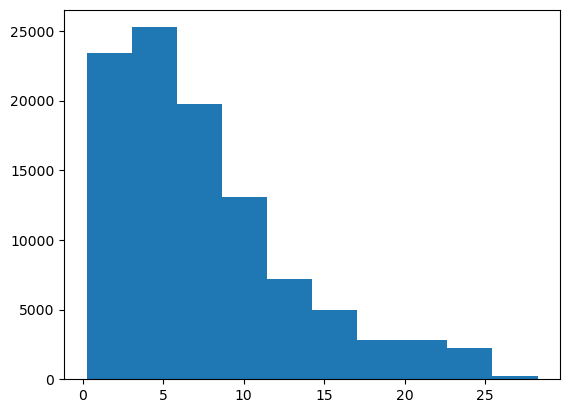

In [226]:
plt.hist(b['peak_cell_slope_avg'])

max abs diff: 0.0


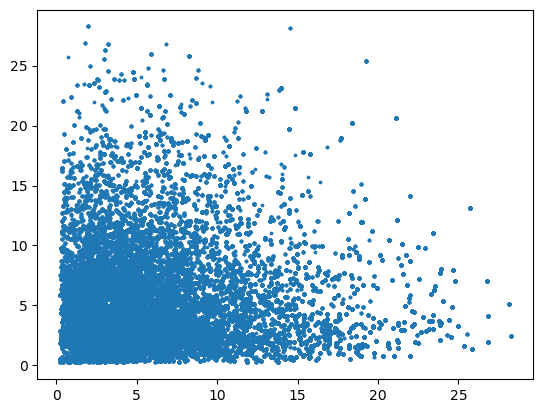

In [216]:
plt.scatter(b['peak_cell_slope_avg'], c['peak_cell_slope_avg'], s=3)
print("max abs diff:", np.abs(a['rainpeak_peak_value'] - b['rainpeak_peak_value']).max())

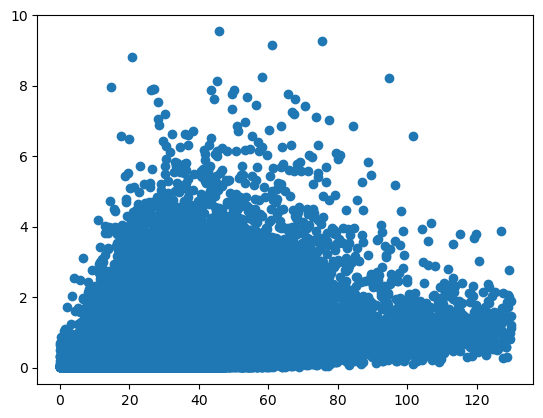

In [231]:
plt.scatter(rainfall_events_all_new_df['floodpeak_max_precip'], rainfall_events_all_new_df['floodpeak_10cm_area'])